#  Experiment 5: Supervised Learning – Regression with scikit-learn

---
### **Aim / Objective:**
To implement Linear and Polynomial Regression, predict continuous outcomes, and evaluate models using MAE, MSE, and R-squared scores.

---
### **Theory & Overview:**
Regression models continuous target variables:
- **Simple & Multiple Linear Regression**: Fits $y = \mathbf{w}^T \mathbf{x} + b$ by minimizing the Residual Sum of Squares (RSS).
- **Polynomial Regression**: Captures non-linear curves by transforming inputs into higher-degree polynomial features $\phi(x) = [1, x, x^2, \dots, x^d]$.
- **Evaluation Metrics**:
  - Mean Absolute Error (MAE): $\frac{1}{n} \sum |y_i - \hat{y}_i|$
  - Mean Squared Error (MSE): $\frac{1}{n} \sum (y_i - \hat{y}_i)^2$
  - Coefficient of Determination ($R^2$ Score): $1 - \frac{SS_{res}}{SS_{tot}}$



### **1. Synthetic Non-Linear Data Generation**


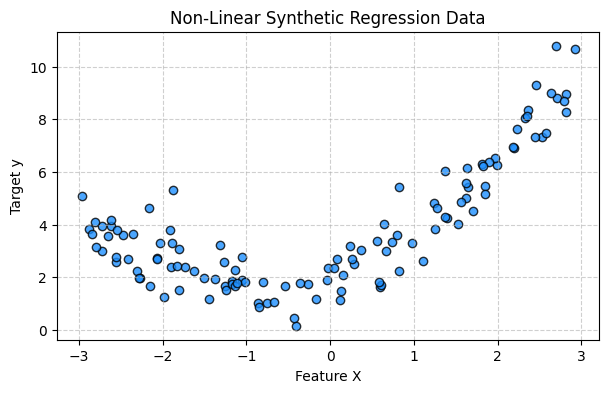

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
X = 6 * np.random.rand(120, 1) - 3
y = 0.6 * X**2 + X + 2 + np.random.randn(120, 1) * 0.8

plt.figure(figsize=(7, 4))
plt.scatter(X, y, color='dodgerblue', edgecolor='k', alpha=0.8)
plt.title("Non-Linear Synthetic Regression Data")
plt.xlabel("Feature X")
plt.ylabel("Target y")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



### **2. Linear vs. Polynomial Regression Implementation**


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 1. Standard Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

# 2. Polynomial Regression (Degree = 2)
poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly_features.fit_transform(X_train)
X_test_poly = poly_features.transform(X_test)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)
y_pred_poly = poly_reg.predict(X_test_poly)

print("Linear Model Fitted.")
print("Polynomial Model Fitted.")



Linear Model Fitted.
Polynomial Model Fitted.


### **3. Visualizing Model Fit & Evaluation**


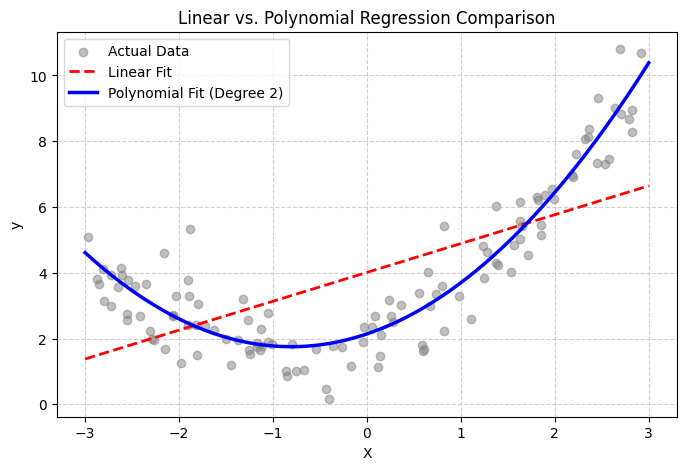

  Metric  Linear Regression  Polynomial Regression
     MAE           1.398846               0.656586
     MSE           2.815420               0.625790
R² Score           0.504456               0.889854


In [ ]:
# Generate smooth curve for plotting
X_new = np.linspace(-3, 3, 200).reshape(-1, 1)
y_new_lin = lin_reg.predict(X_new)
y_new_poly = poly_reg.predict(poly_features.transform(X_new))

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='gray', alpha=0.5, label='Actual Data')
plt.plot(X_new, y_new_lin, 'r--', linewidth=2, label='Linear Fit')
plt.plot(X_new, y_new_poly, 'b-', linewidth=2.5, label='Polynomial Fit (Degree 2)')
plt.title("Linear vs. Polynomial Regression Comparison")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Evaluation Metrics Table
import pandas as pd
metrics = {
    'Metric': ['MAE', 'MSE', 'R² Score'],
    'Linear Regression': [
        mean_absolute_error(y_test, y_pred_lin),
        mean_squared_error(y_test, y_pred_lin),
        r2_score(y_test, y_pred_lin)
    ],
    'Polynomial Regression': [
        mean_absolute_error(y_test, y_pred_poly),
        mean_squared_error(y_test, y_pred_poly),
        r2_score(y_test, y_pred_poly)
    ]
}

print(pd.DataFrame(metrics).to_string(index=False))



---
### **Conclusion & Learning Outcomes:**
Demonstrated that standard Linear Regression underfits curved relationships, whereas Polynomial Regression effectively captures non-linear dynamics, evidenced by a significant reduction in MSE and an improved R² score.


### **Result / Interpretation:**
The test-set results show that Polynomial Regression performs better than Linear Regression:

- **Linear Regression:** MAE = 1.3988, MSE = 2.8154, R² = 0.5045
- **Polynomial Regression (degree 2):** MAE = 0.6566, MSE = 0.6258, R² = 0.8899

Polynomial Regression has lower MAE and MSE and a higher R² score. Therefore, it models this quadratic relationship more accurately than the straight-line Linear Regression model.
